<a href="https://colab.research.google.com/github/jyuis212/antigravity-study/blob/main/%E1%84%83%E1%85%A6%E1%84%8B%E1%85%B5%E1%84%90%E1%85%A5%E1%84%80%E1%85%AA%E1%84%92%E1%85%A1%E1%86%A8%E1%84%80%E1%85%AA_%E1%84%8B%E1%85%B5%E1%86%AB%E1%84%80%E1%85%A9%E1%86%BC%E1%84%8C%E1%85%B5%E1%84%82%E1%85%B3%E1%86%BC_6%E1%84%8C%E1%85%AE%E1%84%8E%E1%85%A1_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6주차 실습 — Pandas (2): 데이터 정제와 기술통계

**데이터과학과 인공지능 · 2026-2학기**

---

이번 주도 **녹화강의**입니다. 영상을 보면서 직접 따라 실행하세요.

> 1. LMS에서 파일을 다운로드한다.
> 2. 다운로드된 파일을 내 구글드라이브에 업로드한다.
> 3. 구글드라이브에서 파일을 우클릭하고, 연결앱에서 Google Colaboratory를 클릭한다.
> 4. 연결앱이 보이지 않는 경우, 구글에서 Colab을 검색하여 사이트에 접속한 후(https://colab.research.google.com/) 노트 업로드에서 아까 다운로드 받은 파일선택  

### 오늘은 "지저분한 데이터"를 받습니다

5주차에 쓴 카페 데이터는 **제가 깨끗하게 만들어 드린 것**이었습니다. 빈칸도 없고 오타도 없었죠.

현실의 데이터는 그렇지 않습니다. 오늘 받을 파일에는 이런 것들이 섞여 있습니다.

- 값이 **비어 있는** 칸
- **똑같은 행이 두 번** 들어간 경우
- `"커피"` 와 `"커 피"` 처럼 **같은 뜻인데 다르게 적힌** 값
- `4,500` 처럼 **쉼표 때문에 숫자가 아닌 글자로 읽히는** 열

실무에서 데이터 분석 시간의 **절반 이상이 이 정리 작업**이라는 말이 있습니다. 과장이 아닙니다.


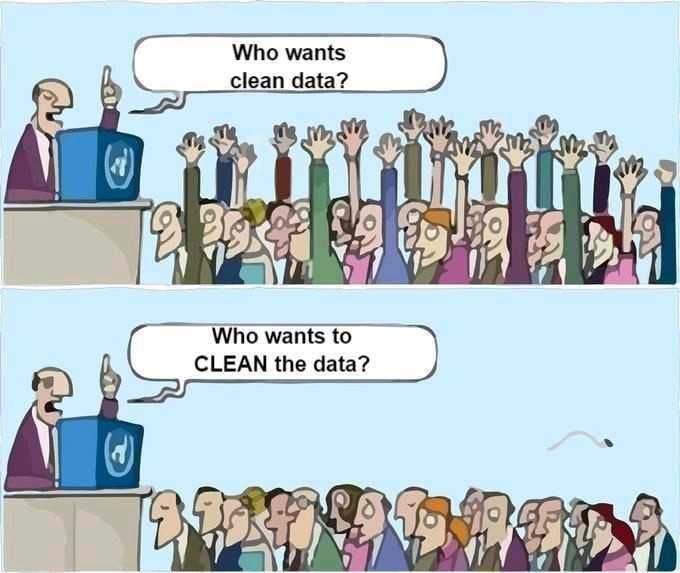


### 오늘의 목표

- 데이터의 **빈칸(결측치)** 을 찾고, 어떻게 할지 **판단**한다
- **중복된 행**을 찾아 지운다
- **표기가 흔들리는 값**을 하나로 통일한다
- 글자로 읽힌 숫자를 **진짜 숫자로** 바꾼다
- `describe()` 로 데이터를 **요약**한다
- `groupby()` 로 **그룹별로 비교**한다

### 지난주 복습

이번 주 내내 쓰는 것들입니다.

| 지난주에 배운 것 | 오늘 이렇게 씁니다 |
|---|---|
| `df["열"]` 로 열 꺼내기 | 정제할 열을 고를 때 |
| `df[조건]` 으로 행 고르기 | 문제가 있는 행을 찾을 때 |
| `df.loc[조건, "열"] = 값` | 특정 행의 값을 고칠 때 |
| `value_counts()` | 이상한 값이 섞였는지 확인할 때 |

---
## 0. 5주차 실습 과제




### 문제 1

`df` 에서 `메뉴`, `매장`, `매출` 세 열만 꺼내 앞 5줄을 출력하세요.

In [ ]:
print(df[["메뉴", "매장", "매출"]].head())

### 문제 2

`분류` 가 `"커피"` 이면서 `매출` 이 100000원 이상인 행이 몇 개인지 출력하세요.

In [ ]:
조건 = df[(df["분류"] == "커피") & (df["매출"] >= 100000)]
print(len(조건))

---
## 1. 지저분한 데이터 만나기

아래 셀은 **그냥 실행**하세요.

In [ ]:
# 설정 셀 — 그냥 실행만 하세요
import random
random.seed(66)

메뉴정보 = {
    "아메리카노": ("커피", 4500), "카페라떼": ("커피", 5000),
    "바닐라라떼": ("커피", 5500), "콜드브루": ("커피", 5000),
    "녹차라떼": ("논커피", 5500), "초코라떼": ("논커피", 5500),
    "자몽에이드": ("논커피", 6000), "복숭아아이스티": ("논커피", 4500),
}
요일표 = ["월", "화", "수", "목", "금"]
좋은후기 = ["맛이 깔끔하고 좋았어요", "직원분이 친절하셨습니다", "자리가 넓어서 공부하기 좋아요",
          "가격 대비 양이 넉넉합니다", "향이 진하고 맛있어요", "분위기가 조용해서 좋네요"]
보통후기 = ["무난한 맛입니다", "그냥 평범했어요", "가격은 적당한 편", "다시 올지는 모르겠네요"]
나쁜후기 = ["대기 시간이 너무 길었어요", "맛이 생각보다 밍밍합니다", "자리가 없어서 서서 마셨어요",
          "가격에 비해 아쉬웠습니다", "주문이 잘못 나왔어요"]

행들 = []
for 주 in range(3):
    for i, 요일 in enumerate(요일표):
        날짜 = f"2026-03-{2 + 주 * 7 + i:02d}"
        for 매장 in ["안암점", "정문점"]:
            for 메뉴 in random.sample(list(메뉴정보), 3):
                분류, 가격 = 메뉴정보[메뉴]
                수량 = random.randint(5, 45)
                결제 = random.choice(["카드", "현금", "간편결제"])
                평점 = random.choices([1, 2, 3, 4, 5], weights=[3, 7, 20, 40, 30])[0]
                후기 = random.choice(좋은후기 if 평점 >= 4 else (보통후기 if 평점 == 3 else 나쁜후기))
                행들.append([날짜, 요일, 매장, 메뉴, 분류, f"{가격:,}", str(수량), 결제, str(평점), 후기])

# ── 현실의 데이터처럼 어지럽힙니다 ──
for idx in random.sample(range(len(행들)), 8):      # 수량 빈칸
    행들[idx][6] = ""
for idx in random.sample(range(len(행들)), 6):      # 평점 빈칸
    행들[idx][8] = ""
for idx in random.sample(range(len(행들)), 12):     # 분류 표기 흔들림
    행들[idx][4] = random.choice([" 커피", "커 피", "논 커피", "논커피 "]) \
        if 행들[idx][4] == "커피" else random.choice(["논 커피", "논커피 ", " 논커피"])
for idx in random.sample(range(len(행들)), 7):      # 매장 표기 흔들림
    행들[idx][2] = 행들[idx][2][:2] + " " + 행들[idx][2][2:]
for idx in random.sample(range(len(행들)), 20):     # 후기 앞뒤 공백
    행들[idx][9] = "  " + 행들[idx][9] + " "
for idx in random.sample(range(len(행들)), 4):      # 중복 입력
    행들.append(list(행들[idx]))

def 칸(v):                      # 값 안에 쉼표가 있으면 따옴표로 감쌉니다
    return f'"{v}"' if "," in v else v

머리 = "날짜,요일,매장,메뉴,분류,가격,수량,결제수단,평점,후기"
with open("cafe_sales_messy.csv", "w", encoding="utf-8") as f:
    f.write(머리 + "\n" + "\n".join(",".join(칸(x) for x in r) for r in 행들))

print(f"cafe_sales_messy.csv 생성 완료 — 총 {len(행들)}행")

In [ ]:
import pandas as pd

df = pd.read_csv("cafe_sales_messy.csv")
df.head(10)

겉보기에는 5주차 데이터와 비슷합니다. 문제는 **눈으로는 잘 안 보인다**는 것입니다.

--> 정제 작업은 항상 `info()` 부터 시작합니다.

In [ ]:
df.info()

여기서 두 가지를 읽어야 합니다.

**① `Non-Null Count` 를 보세요.** 전체 행 수보다 작은 열이 있다면 **빈칸이 있다**는 뜻입니다.

**② `Dtype` 을 보세요.** `가격`, `수량`, `평점` 은 숫자여야 하는데 어떻게 나왔나요?

`가격` 이 글자(`object` 또는 `str`)로 읽혔습니다. 쉼표 때문입니다. 이 상태로는 계산이 안 됩니다.

In [ ]:
# 글자로 읽힌 가격은 계산이 안 됩니다. 일부러 해봅시다
df["가격"] * 2

`5,0005,000` 처럼 **같은 글자가 두 번 이어붙었습니다.** 2를 곱한 게 아니라 글자를 두 번 반복한 것입니다. 4주차에 `"20" + "5"` 가 `205` 가 됐던 그 문제입니다.

오늘 할 일을 순서대로 정리하면 이렇습니다.

| 순서 | 할 일 | 왜 |
|---|---|---|
| 1 | 중복 행 지우기 | 같은 게 두 번 세어지면 모든 합계가 틀어짐 |
| 2 | 표기 통일하기 | `"커피"` 와 `"커 피"` 가 다른 값으로 세어짐 |
| 3 | 자료형 바로잡기 | 글자로는 계산이 안 됨 |
| 4 | 빈칸 처리하기 | 어떻게 할지 **판단**이 필요 |
| 5 | 요약하고 비교하기 | 여기서부터가 진짜 분석 |



---
## 2. 빈칸(결측치) 다루기



### 2.1. 빈칸 찾기

비어 있는 칸을 **결측치**(missing value)라고 합니다. Pandas는 이걸 `NaN` 으로 표시합니다.

`isna()` 는 "이 칸이 비었니?"를 묻고 **True/False** 를 돌려줍니다. 5주차 조건 필터링과 같은 구조입니다.

In [ ]:
df.isna().head()

이걸 그대로 보면 알아보기 어렵습니다. **열마다 몇 개인지 세는 게** 실용적입니다.

In [ ]:
df.isna().sum()

5주차 3.2절에서 다룬 **점이 연달아 나오는 코드**입니다. 왼쪽부터 읽으면

```
df . isna()  . sum()
│     │         │
│     │         └─ True가 몇 개인지 세어줘
│     └─────────── 빈칸인지 표시해줘
└───────────────── 표에게
```

`True` 는 1로 취급되므로, 더하면 곧 "빈칸 개수"가 됩니다.

### 2.2. 빈칸인 행을 직접 보기

개수만 아는 것으로는 부족하겠죠? **어떤 행이 비었는지** 봐야 판단할 수 있습니다.

In [ ]:
df[df["수량"].isna()]

### 2.3. 어떻게 할지 **판단**하기


선택지는 셋입니다.

| 방법 | 코드 | 언제 |
|---|---|---|
| **그대로 둔다** | — | 그 열을 안 쓰거나, 빈칸 자체가 정보일 때 |
| **행을 지운다** | `dropna()` | 그 값이 없으면 그 행을 쓸 수 없을 때 |
| **값을 채운다** | `fillna()` | 합리적인 추정값이 있을 때 |


우리 데이터로 생각해 봅시다.

**`수량` 이 빈 행** — 몇 잔 팔렸는지 모르면 매출을 계산할 수 없습니다. 평균으로 채울 수도 있지만, 그러면 **실제로 측정되지 않은 숫자가 분석에 들어갑니다.** 전체 90여 행 중 8건이니 지우는 것이 좋겠습니다.

**`평점` 이 빈 행** — 평점은 고객이 **자율적으로** 남긴 것입니다. 안 남긴 데에는 이유가 있을 수 있습니다. 여기에 평균 3.9를 채워 넣으면, **아무 말도 안 한 사람이 "보통쯤 만족했다"고 말한 것처럼** 되어버립니다.

> ###  생각해볼 질문
>
> 설문에서 특정 문항만 유독 응답률이 낮다면, 그 빈칸은 "실수로 빠뜨린 것"일까요, 아니면 **"답하기 불편한 질문이었다"는 정보** 일까요?
>
> 심리학·사회조사에서 **무응답 자체가 데이터**인 경우가 많습니다.
> **빈칸을 어떻게 처리했는지는 보고서에 반드시 밝혀야 합니다.**  



### 2.4. 실제로 처리하기

In [ ]:
print("처리 전:", df.shape)

# 수량이 빈 행만 지웁니다. subset= 으로 열을 지정합니다
df = df.dropna(subset=["수량"])

print("처리 후:", df.shape)
print()
print(df.isna().sum())

`df = df.dropna(...)` 처럼 **다시 `df` 에 담았다**는 점을 보세요.

Pandas 메서드는 대부분 **원본은 그대로 두고 바뀐 사본을 돌려줍니다.** 담지 않으면 아무 일도 일어나지 않습니다.

`subset=["수량"]` 을 빼면 **어느 열이든 빈칸이 있는 행이 전부** 지워집니다. 평점 결측 행까지 날아갑니다. 조심하세요.

In [ ]:
# 참고: 채우는 방법도 알아두세요
예시 = df.copy()
예시["평점"] = 예시["평점"].fillna(0)      # 0으로 채우기
print(예시["평점"].value_counts().head())

**0으로 채우면 안 되는 이유**가 여기서 바로 보입니다. 평점은 1~5점인데 **0점이라는 없던 등급이 생겼습니다.** 평균을 내면 실제보다 훨씬 낮게 나옵니다.

`fillna()` 를 쓸 때는 **그 값이 말이 되는지** 반드시 확인하세요.

### ⏸ 직접 해보세요 (1)

1. 현재 `df` 에 남아 있는 결측치가 열별로 몇 개인지 출력하세요
2. `평점` 이 비어 있는 행만 골라서 **몇 행인지** 출력하세요

In [ ]:
# TODO 1.

# TODO 2.
평점빈칸 =  df[df["평점"].isna()]


---
## 3. 중복 행 지우기

같은 데이터가 두 번 입력되는 일은 흔합니다. 파일을 합치다가, 또는 입력 실수로요.

중복이 남아 있으면 **합계와 평균이 전부 틀어집니다.**

`duplicated()` 는 "이 행이 앞에 나온 행과 똑같니?"를 묻습니다.

In [ ]:
print("중복 행 개수:", df.duplicated().sum())

In [ ]:
# 어떤 행이 중복인지 직접 봅시다
df[df.duplicated()]

`duplicated()` 는 **두 번째 등장부터** True로 표시합니다. 첫 번째는 남겨야 하니까요.

지울 때는 `drop_duplicates()` 를 씁니다.

In [ ]:
print("처리 전:", df.shape)

df = df.drop_duplicates()

print("처리 후:", df.shape)
print("남은 중복:", df.duplicated().sum())

> **주의**: 모든 중복이 오류인 건 아닙니다. 같은 손님이 같은 메뉴를 두 번 산 기록이라면 **진짜 두 건**입니다.
>
> 우리 데이터는 "하루 한 매장에서 한 메뉴가 팔린 집계"이므로, 날짜·매장·메뉴가 모두 같은 행이 두 개일 수는 없습니다. 그래서 지우는 게 맞습니다.
>
> **데이터의 1행이 무엇을 뜻하는지 알아야** 이 판단을 할 수 있습니다.

---
## 4. 표기 통일하기

### 4.1. 문제 발견하기

5주차에서 `value_counts()` 를 배울 때, "오타가 섞였는지 한눈에 보인다"고 했습니다. 실제로 확인해 봅시다.

In [ ]:
df["분류"].value_counts()

**`커피` 와 `논커피` 두 개여야 하는데 훨씬 많이 나왔습니다.**

`" 커피"`(앞에 공백), `"커 피"`(중간에 공백), `"논커피 "`(뒤에 공백)가 전부 **다른 값**으로 세어지고 있습니다. 사람 눈에는 같아 보여도 컴퓨터에게는 완전히 다른 글자입니다.

이 상태로 분석하면 "커피가 43건"이 아니라 "커피 35건, 커 피 5건, ..." 이 됩니다.

매장도 확인해 봅시다.

In [ ]:
df["매장"].value_counts()

### 4.2. 앞뒤 공백 없애기 — `.str.strip()`

가장 흔한 문제는 **앞뒤 공백**입니다. 엑셀에서 복사해 오거나 사람이 입력할 때 자주 생깁니다.

`.str.strip()` 이 앞뒤 공백을 잘라냅니다.

In [ ]:
df["분류"] = df["분류"].str.strip()
df["매장"] = df["매장"].str.strip()
df["후기"] = df["후기"].str.strip()

df["분류"].value_counts()

줄었습니다. 그런데 **`"커 피"` 는 아직 남아 있습니다.** 공백이 가운데 있어서 `strip()` 으로는 안 잡힙니다.

### 4.3. 가운데 공백 없애기 — `.str.replace()`

`.str.replace(바꿀것, 바꿀값)` 으로 공백 자체를 지웁니다.

In [ ]:
df["분류"] = df["분류"].str.replace(" ", "")
df["매장"] = df["매장"].str.replace(" ", "")

print(df["분류"].value_counts())
print()
print(df["매장"].value_counts())

깔끔해졌습니다. `" "` 를 `""`(빈 글자)로 바꾼 것입니다.

> **주의**: 이 방법은 **공백을 다 지워도 되는 열**에만 쓰세요. `후기` 열에 쓰면 모든 단어가 붙어버립니다. 그래서 후기에는 `strip()` 만 썼습니다.

### 4.4. 아예 다른 말로 적힌 경우 — `replace()` 로 통일

공백이 아니라 단어 자체가 다를 때가 있습니다. `"남"` / `"남성"` / `"M"` 같은 경우요.

이때는 딕셔너리로 짝을 지어 바꿉니다.

```python
df["성별"] = df["성별"].replace({"남": "남성", "M": "남성", "여": "여성", "F": "여성"})
```

`.str` 이 없다는 점에 주의하세요. **글자 일부를 고치는 게 아니라 값 전체를 갈아끼우는 것**이라 `.str` 이 필요 없습니다.

### ⏸ 직접 해보세요 (2)

1. `결제수단` 열의 `value_counts()` 를 확인하세요. 표기가 흔들린 값이 있나요?
2. `메뉴` 열도 같은 방법으로 확인하세요
3. 만약 문제가 있다면 `strip()` 으로 정리하세요 (없다면 "문제 없음"을 주석으로 적으세요)

In [ ]:
# TODO 1.

# TODO 2.

# TODO 3.


---
## 5. 자료형 바로잡기



### 5.1. 쉼표 때문에 글자가 된 숫자

1절에서 본 문제입니다. `가격` 이 `"4,500"` 이라는 **글자**로 읽혔습니다.

고치는 순서는 두 단계입니다.

1. **쉼표를 지운다** → `"4500"` (아직 글자)
2. **숫자로 바꾼다** → `4500` (진짜 숫자)

In [ ]:
# 1단계: 쉼표 지우기
print(df["가격"].str.replace(",", "").head(3))
print()

# 2단계: 숫자로 바꾸기 — astype(int)
df["가격"] = df["가격"].str.replace(",", "").astype(int)

print(df["가격"].head(3))
print("자료형:", df["가격"].dtype)

`astype(int)` 가 "정수형으로 바꿔줘"입니다. `int` 는 4주차에 배운 정수형입니다.

이제 계산이 됩니다.

In [ ]:
print(df["가격"] * 2)

### 5.2. 수량도 숫자로

`수량` 은 빈칸이 있었습니다. 빈칸이 섞인 열은 Pandas가 **실수형(`float64`)** 으로 읽습니다. `NaN` 이 실수이기 때문입니다.

그래서 `25.0` 처럼 소수점이 붙습니다. 잔 수에 소수점은 어색하니 정수로 바꿉니다. **빈칸을 이미 지웠으므로 지금은 가능합니다.**

In [ ]:
print("바꾸기 전:", df["수량"].dtype)

df["수량"] = df["수량"].astype(int)

print("바꾼 후:", df["수량"].dtype)
print(df["수량"].head(3).tolist())

> **왜 빈칸이 있으면 `astype(int)` 가 안 되나요?**
>
> `NaN` 은 "값이 없음"이라서 정수로 바꿀 방법이 없습니다. 빈칸을 **지우거나 채운 뒤에** 변환해야 합니다. 순서가 중요한 이유입니다.

`평점` 은 아직 빈칸이 남아 있으니 `float` 그대로 둡니다. 그래도 평균 계산은 됩니다. Pandas가 빈칸을 알아서 빼고 계산하기 때문입니다.

### 5.3. 날짜를 날짜답게 — `to_datetime()`

`날짜` 열은 지금 `"2026-03-02"` 라는 **글자**입니다. 글자라서 월별로 묶거나 기간을 계산할 수 없습니다.

`pd.to_datetime()` 으로 날짜형으로 바꿉니다.

In [ ]:
print("바꾸기 전:", df["날짜"].dtype)

df["날짜"] = pd.to_datetime(df["날짜"])

print("바꾼 후:", df["날짜"].dtype)

날짜형이 되면 `.dt` 를 붙여서 연·월·일을 꺼낼 수 있습니다.

In [ ]:
print(df["날짜"].dt.month.head(3).tolist())        # 월
print(df["날짜"].dt.day.head(3).tolist())          # 일
print(df["날짜"].dt.dayofweek.head(3).tolist())    # 요일 (0=월요일)

> **자주 나는 오류**
>
> `2026년 3월 2일` 이나 `26.03.02` 처럼 형식이 제각각이면 `to_datetime()` 이 실패합니다. 그럴 때는 형식을 알려줍니다.
>
> ```python
> pd.to_datetime(df["날짜"], format="%Y년 %m월 %d일")
> ```
>
> 그래도 안 되면 `errors="coerce"` 를 붙이세요. 변환 못 한 값을 `NaN` 으로 만들고 넘어갑니다.



### 5.4. 정제 끝 — 확인하기

In [ ]:
df.info()

처음과 비교해 보세요.

- 중복 행이 사라졌습니다
- `가격`, `수량` 이 숫자가 되었습니다
- `날짜` 가 날짜형이 되었습니다
- `분류`, `매장` 표기가 통일되었습니다

**이제야 분석을 시작할 수 있습니다.** 매출 열을 만들어 봅시다.

In [ ]:
df

In [ ]:
df["매출"] = df["가격"] * df["수량"]
df.head()

---
## 6. 기술통계 — 데이터를 요약하기



### 6.1. describe()  

`describe()` 는 **숫자 열의 요약**을 한꺼번에 보여줍니다. 새 데이터를 받으면 거의 반드시 돌려보게 됩니다.

In [ ]:
df.describe()

각 줄의 뜻은 이렇습니다.

| 항목 | 뜻 |
|---|---|
| `count` | 값이 있는 개수 (빈칸 제외) |
| `mean` | 평균 |
| `std` | 표준편차 — 값들이 평균에서 얼마나 퍼져 있나 |
| `min` / `max` | 최솟값 / 최댓값 |
| `25%` / `50%` / `75%` | 작은 것부터 줄 세웠을 때 1/4, 절반, 3/4 지점 |

**`50%` 가 중앙값(median)** 입니다. 줄 세웠을 때 한가운데 있는 값이죠.

`평점` 의 `count` 를 보세요. 다른 열보다 작습니다. 빈칸이 남아 있기 때문입니다. **Pandas가 알아서 빼고 계산했습니다.**

### 6.2. 평균과 중앙값 — 왜 둘 다 보나



In [ ]:
print("매출 평균  :", df["매출"].mean())
print("매출 중앙값:", df["매출"].median())

둘이 다릅니다. 왜일까요?

**평균은 극단값에 끌려갑니다.** 한 건이 유난히 크면 평균이 통째로 올라갑니다. 중앙값은 순서만 보기 때문에 그렇지 않습니다.

직접 확인해 봅시다.

In [ ]:
# 매출이 아주 큰 가상의 한 건을 넣어보면?
실험 = df["매출"].tolist()
실험.append(99999999)      # 단체 주문 한 건이 들어왔다고 가정

실험S = pd.Series(실험)
print("평균  :", 실험S.mean(), "  ← 크게 흔들림")
print("중앙값:", 실험S.median(), "  ← 거의 그대로")

**소득, 집값, 조회수처럼 한쪽으로 치우친 데이터는 평균보다 중앙값이 현실을 더 잘 보여줍니다.**

"평균 연봉"과 "중위 연봉"이 크게 다른 이유가 이것입니다. 뉴스에서 어느 쪽을 썼는지 보는 습관을 들이면 좋습니다.

### 6.3. 글자 열 요약하기

`describe()` 는 숫자 열만 보여줍니다. 글자 열은 `value_counts()` 가 담당합니다.

In [ ]:
print(df["메뉴"].value_counts().head())
print()
print(df["결제수단"].value_counts(normalize=True))   # normalize=True → 비율로

`normalize=True` 를 붙이면 개수 대신 **비율**이 나옵니다. "전체의 몇 퍼센트인가"를 볼 때 편합니다.

---
## 7. 그룹별로 비교하기 — groupby



### 7.1. groupby가 하는 일

전체 평균은 알았습니다. 그런데 보통 궁금한 건 이런 것들이죠.

- **매장별로** 매출이 얼마나 다른가
- **커피와 논커피** 중 어느 쪽이 많이 팔리나
- **요일별** 판매량 차이가 있나

`groupby()` 는 **같은 값끼리 묶어서 각각 계산**해 줍니다.

5주차에는 이렇게 했습니다.

```python
df[df["매장"] == "안암점"]["매출"].sum()
df[df["매장"] == "정문점"]["매출"].sum()
```

매장이 10개면 10줄을 써야 합니다. `groupby` 는 한 줄입니다.

In [ ]:
df.groupby("매장")["매출"].sum()

읽는 방법은 왼쪽부터입니다.

```
df . groupby("매장") . ["매출"] . sum()
│       │                 │         │
│       │                 │         └─ 합계를 내줘
│       │                 └─────────── 매출 열에 대해
│       └───────────────────────────── 매장별로 묶어서
└───────────────────────────────────── 표를
```

**"무엇으로 묶어서, 어느 열을, 어떻게 계산할까"** 세 가지만 정하면 됩니다.

In [ ]:
print(df.groupby("분류")["수량"].mean())
print()
print(df.groupby("요일")["매출"].sum())
print()
print(df.groupby("메뉴")["매출"].sum().sort_values(ascending=False))

마지막 줄에 `sort_values()` 를 붙였습니다. 그룹 결과도 정렬할 수 있습니다.

### 7.2. 여러 계산을 한 번에 — agg()

합계만, 평균만 보는 게 아니라 여러 개를 같이 보고 싶을 때가 많습니다.

In [ ]:
df.groupby("매장")["매출"].agg(["sum", "mean", "count"])

`agg()` 안에 원하는 계산을 리스트로 넣으면 됩니다. 쓸 수 있는 것은 `"sum"`, `"mean"`, `"median"`, `"min"`, `"max"`, `"count"`, `"std"` 등입니다.

**`count` 를 꼭 같이 보세요.** 평균만 보면 그게 몇 건에서 나온 평균인지 알 수 없습니다.

### 7.3. 두 개 이상으로 묶기

묶는 기준을 리스트로 주면 여러 단계로 묶입니다.

In [ ]:
df.groupby(["매장", "분류"])["매출"].sum()

### 7.4. 결과가 표처럼 안 보일 때

`groupby` 결과는 보통 **Series**(5주차 2절)입니다. 다시 표로 만들려면 `reset_index()` 를 붙입니다.

In [ ]:
결과 = df.groupby("매장")["매출"].sum().reset_index()
print(type(결과))
결과

### 7.5. 수치를 해석할 때 — 주의할 점

매장별 평균 평점을 비교해 봅시다.

In [ ]:
df.groupby("매장")["평점"].agg(["mean", "count"])

차이가 보이나요? 그렇다면 **"안암점 만족도가 더 높다"고 말해도 될까요?**

두 가지를 먼저 따져야 합니다.

**① 건수가 충분한가.** `count` 를 보세요. 각 매장 40여 건입니다. 그리고 그중 평점을 남긴 사람만 세어진 것입니다. 몇 건 차이는 우연히도 생깁니다.

**② 평점을 남긴 사람이 누구인가.** 5주차 데이터 설명서에서 봤듯이, 평점은 **자율 제출**입니다. 아주 만족했거나 아주 불만인 사람이 주로 남깁니다. 그 비율이 매장마다 다르면 평균도 달라집니다.

>
>
> 그래서 이 수업에서는 **"차이가 보인다"** 까지만 말하고 **"차이가 있다"** 고는 하지 않습니다.
>
> 보이는 차이가 우연인지 아닌지를 판단하는 것이 **추론통계**이고, 심리통계·사회통계 같은 과목에서 배웁니다. 지금 우리가 하는 것은 **기술통계** — 데이터에 있는 것을 정확히 요약하는 일까지입니다.
>

### ⏸ 직접 해보세요 (3)

1. `결제수단` 별 매출 합계를 구하세요
2. `요일` 별 평균 수량을 구하되, **건수(`count`)도 같이** 나오게 하세요
3. `매장` 과 `결제수단` 두 가지로 묶어서 매출 합계를 구하세요
4. 2번 결과를 보고 **"특정 요일이 더 잘 팔린다"고 말할 수 있을지** 한 줄로 적어보세요

In [ ]:
# TODO 1.

# TODO 2.

# TODO 3.



---
## 8. 정제 결과 저장하기, 그리고 7주차 과제  

정제한 데이터는 저장해 두면 다음에 다시 정리할 필요가 없습니다.

In [ ]:
df.to_csv("cafe_sales_clean.csv", index=False, encoding="utf-8-sig")
print("저장 완료 —", df.shape)



> **원본은 절대 덮어쓰지 마세요.** 정제한 파일은 **새 이름**으로 저장합니다. 정제 과정에서 실수했을 때 돌아갈 곳이 있어야 합니다.

---

## 7주차 전까지 해올 것 (과제)

7주차는 **실시간 수업**이고, 여러분이 3주차에 고른 **도메인 데이터를 직접 다루는 날**입니다. 그 전에 한 가지만 해오세요.

### ① 내 데이터를 코랩에서 열어보기

새 노트북을 하나 만들고, 자기 데이터를 불러와서 아래 세 줄을 실행해보세요.

```python
import pandas as pd
df = pd.read_csv("내파일.csv")      # 또는 pd.read_excel("내파일.xlsx")

print(df.shape)
print(df.info())
df.head()
```

잘 안 되면 **오류 메시지를 통째로 복사해서 LMS Q&A에 올려주세요.** 7주차 수업 앞부분에서 자주 나온 문제를 모아서 같이 해결합니다.

파일을 못 여는 상태로 와도 괜찮습니다. **시도한 기록**과 **오류 메시지**만 가져오시면 됩니다.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/AP/서울시 문화재 관리 현황.csv", encoding="cp949", encoding_errors="replace")

,문화재번호,문화재명,문화재명(한자),문화재명(영문),자치단체코드,자치단체명칭,gps 경도,gps 위도,소재지/보관장소,소재지(도로명),...,동산구분,분류(항일독립 등),종교,소유구분,관리자구분,처리상태코드,처리상태명,취득경위,확인사유,비고
0,SE2019CM00094,지장사 아미타불도,地藏寺 阿彌陀佛圖,NaN,SE012,동작구,126.970988,37.499285,"서울특별시 동작구 현충로 210 (동작동, 호국지장사)",서울특별시 동작구 현충로 210(동작동),...,동산,NaN,불교,CA9004,CA9004,DSGPS7010,기지정 문화재 등록완료,NaN,NaN,NaN
1,SE2019CM00095,지장사 극락구품도,地藏寺 極樂九品圖,NaN,SE012,동작구,126.970988,37.499285,서울특별시 동작구 동작동 산41-2 국립서울현충원,서울특별시 동작구 현충로 210(동작동),...,동산,NaN,불교,CA9004,CA9004,DSGPS7010,기지정 문화재 등록완료,NaN,NaN,NaN
2,SE2019CM00096,지장사 감로도,地藏寺 甘露圖,NaN,SE012,동작구,126.970988,37.499285,서울특별시 동작구 동작동 산41-2 국립서울현충원,서울특별시 동작구 현충로 210(동작동),...,동산,NaN,불교,CA9004,CA9004,DSGPS7010,기지정 문화재 등록완료,NaN,NaN,NaN
3,SE2019CM00097,지장사 지장시왕도,地藏寺 地藏十王圖,NaN,SE012,동작구,126.970988,37.499285,서울특별시 동작구 동작동 산41-2 국립서울현충원,서울특별시 동작구 현충로 210(동작동),...,동산,NaN,불교,CA9004,CA9004,DSGPS7010,기지정 문화재 등록완료,NaN,NaN,NaN
4,SE2019CM00098,지장사 대웅전 신중도,地藏寺 大雄殿 神衆圖,NaN,SE012,동작구,126.970988,37.499285,서울특별시 동작구 동작동 산41-2 국립서울현충원,서울특별시 동작구 현충로 210(동작동),...,동산,NaN,불교,CA9004,CA9004,DSGPS7010,기지정 문화재 등록완료,NaN,NaN,NaN


In [ ]:
# 본인 데이터 열어서 아래 세 줄 돌려보기.
import pandas as pd
df = pd.read_csv("내파일.csv")      # 또는 pd.read_excel("내파일.xlsx")

# print(df.shape)
# print(df.info())
# df.head()

---
## 10. 자주 묻는 질문 (FAQ)

여러분이 **실제로 적어준 질문들**입니다. 자기 질문이 있는지 찾아보세요.

.


### Q1. `f` 는 무슨 뜻인가요?

**format**(형식)의 f입니다. "이 문자열 안에 값을 끼워넣어 형식을 만들어라"라는 표시입니다.

### Q2. f-문자열에서 따옴표는 어디까지 묶나요?

**문장 전체를 따옴표로 묶고, 변수만 중괄호로 감쌉니다.** 중괄호는 따옴표 안에 들어갑니다.

```python
print(f"저는 {이름}이고 {나이}살입니다")
       │ └────────────┘
       f    전체를 따옴표로 묶음
```


In [ ]:
이름 = "김고려"
나이 = 20

print(f"저는 {이름}이고 {나이}살입니다")       # 올바름
print(f"내년에는 {나이 + 1}살입니다")          # 계산도 가능
print(f"{이름}님, 평균은 {25.8111:.1f}입니다")  # :.1f = 소수점 1자리까지

`:.0f` 는 소수점 없이, `:.2f` 는 둘째 자리까지입니다. `:.숫자f` 형태로 기억하세요.

---

### Q2. 리스트 인덱스는 왜 0부터 시작하나요?

인덱스를 **"처음부터 얼마나 떨어져 있는가"** 로 보기 때문입니다. 첫 번째 값은 처음에서 0만큼 떨어져 있으니 0번입니다.

불편해 보이지만 익숙해지면 계산이 편해집니다. 지금은 **"첫 번째가 0번"** 만 외우세요.

### Q3. 슬라이싱 `[1:3]` 은 왜 3번을 포함하지 않나요?

이것도 "떨어진 거리"로 생각하면 맞아떨어집니다. `[1:3]` 은 **1번 자리에서 3번 자리 직전까지**입니다.

실용적인 장점이 있습니다. `[0:3]` 과 `[3:6]` 처럼 이어 붙이면 **겹치거나 빠지는 값 없이** 딱 나뉩니다.


In [ ]:
점수들 = [88, 92, 75, 100, 64]

print(점수들[1], 점수들[4])      # 두 번째와 다섯 번째
print(점수들[1:3])               # 연속된 구간은 슬라이싱

---

### Q3. `print(점수들)` 했더니 대괄호까지 나옵니다

`[88, 92, 75]` 처럼 나오는 건 **"이것은 리스트입니다"** 라는 표시입니다. 리스트 자체를 통째로 보여준 것이죠.

값만 꺼내려면 인덱스를 쓰거나, for문으로 하나씩 꺼내면 됩니다.

In [ ]:
점수들 = [88, 92, 75]

print(점수들)          # 리스트 통째로
print(점수들[0])       # 값 하나

for 점수 in 점수들:    # 하나씩
    print(점수)

### Q4. 평균을 바로 구하는 방법은 없나요?

`sum() / len()` 말고 더 간단한 방법이 있습니다. **다만 리스트에는 없고 Pandas Series에는 있습니다.**

In [ ]:
점수들 = [88, 92, 75, 100, 64]

print(sum(점수들) / len(점수들))     # 리스트는 이 방법

import pandas as pd
print(pd.Series(점수들).mean())      # Series로 바꾸면 .mean() 하나로 끝
print(df["수량"].mean())             # 그래서 Pandas가 편합니다

---

### Q5. `for 메뉴 in 메뉴들:` 에서 `메뉴` 는 바깥에서도 쓸 수 있나요?

네, 쓸 수는 있습니다. 반복이 끝난 뒤에는 **마지막 값이 남아 있습니다.**

다만 반복문 안에서 쓰라고 만든 이름이니, 바깥에서 쓰는 건 권하지 않습니다. 헷갈립니다.

In [ ]:
메뉴들 = ["아메리카노", "라떼", "녹차라떼"]

for 메뉴 in 메뉴들:
    pass

print(메뉴)     # 마지막 값이 남아 있습니다

### Q6. `#` 뒤에 쓴 글은 왜 실행이 안 되나요?

`#` 뒤는 **주석**입니다. 컴퓨터는 무시하고, 사람이 읽으라고 남기는 메모입니다.

한 줄 전체를 주석으로 만들거나, 코드 뒤에 설명을 붙일 때 씁니다.



### Q7. `"아메리카노"[0]` 처럼 글자도 잘라낼 수 있나요?

됩니다. **문자열은 글자들의 리스트처럼 동작합니다.** 인덱싱도 슬라이싱도 됩니다.

In [ ]:
메뉴 = "아메리카노"

print(메뉴[0])      # 첫 글자
print(메뉴[-1])     # 마지막 글자
print(메뉴[0:3])    # 앞 세 글자

### Q8. 오류가 났는데 어떻게 고칠지 모르겠습니다

**오류 이름은 알겠는데 고치는 게 어렵다**는 의견이 많았습니다. 자주 나오는 것만 정리합니다.

| 오류 | 보통 원인 | 고치는 법 |
|---|---|---|
| `NameError` | 위 셀 미실행, 오타 | 위 셀부터 다시 실행 (0.3절) |
| `TypeError` (`+` 관련) | 글자와 숫자를 더함 | f-문자열로 바꾸기 |
| `TypeError` (`not callable`) | 속성에 괄호를 붙임 | 괄호 빼기 |
| `TypeError` (`&` 관련) | 조건에 괄호를 안 씌움 | 각 조건을 `( )` 로 감싸기 |
| `IndexError` | 없는 번호를 부름 | `len()` 으로 개수 확인 |
| `KeyError` | 없는 열 이름을 부름 | `df.columns` 로 철자 확인 |
| `SyntaxError` | 괄호·따옴표·콜론 누락 | **그 줄과 바로 윗줄**을 확인 |
| `IndentationError` | 들여쓰기 누락 | `for` 아래 줄에 Tab |

**AI에게 물을 때는** 코드 전체와 오류 메시지를 **마지막 줄까지 통째로** 붙여넣으세요. 그리고 받은 코드는 반드시 실행해서 확인하세요.

---

수고하셨습니다.

다음 주 7주차는 **실시간 수업**입니다. 여러분이 고른 도메인 데이터를 직접 불러오고, 데이터 시각화를 시작합니다. 8절의 과제를 꼭 해오세요.

그동안 쌓인 질문은 7주차 앞부분에서 함께 정리합니다. **Q&A 게시판에 편하게 올려주세요.**